[![Open in molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/adriansousapoza/tgmm/blob/main/notebooks/13_model_selection.py)

# Model Selection: BIC, AIC, and ICL

How many components should a mixture have, and which covariance structure? `tgmm.select_model` fits a `GaussianMixture` for every requested `n_components` (and, optionally, every `covariance_type`), records `bic`, `aic` and `icl` for each fit, and returns the best one. This notebook compares the three criteria on a dataset built to make them disagree, including the Integrated Completed Likelihood, `GaussianMixture.icl` (Biernacki, Celeux & Govaert, 2000).

BIC and AIC score a fitted mixture purely on log-likelihood plus a complexity penalty -- they don't care whether the mixture's components are cleanly separated or heavily overlapping, as long as the extra components earn their keep in likelihood. ICL adds an entropy penalty for *ambiguous* assignments (`-2 * sum_i log(responsibility of the point's most likely component)`), so on data with overlapping clusters it tends to prefer **fewer, better-separated** components than BIC does on the same data, even though both coincide when clusters are perfectly separated (one-hot responsibilities).

**What you'll learn**

- how to sweep `n_components` with `select_model` and read its results table
- how BIC, AIC and ICL differ, and why ICL prefers well-separated partitions
- how to compute `icl` (hard and soft) on a single fitted model

**Prerequisites:** [01 -- Gaussian Mixture Models](01_gmm.ipynb), [06 -- Clustering Metrics](06_metrics.ipynb).
See also the [Clustering Metrics user guide](../user-guide/clustering-metrics.md).

## Setup

The next cell imports what the notebook needs and fixes the random seeds. It expects `tgmm` to be importable: `pip install tgmm`, or `pip install -e .` from a clone of the repository. Opened with `marimo edit --sandbox`, the dependencies listed in the header of this file are installed automatically.

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from tgmm import GaussianMixture, generate_gmm_data, select_model
from tgmm.plotting import CATEGORICAL_PALETTE

device = 'cuda' if torch.cuda.is_available() else 'cpu'
plt.rcParams['figure.dpi'] = 100  # tgmm's theme uses 300 dpi; marimo embeds figures at 2x, so keep outputs small
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
print(f'Using device: {device}')

Using device: cpu


## A dataset with overlapping blobs

Five true components in two dimensions: two pairs that overlap substantially (`(0, 0)`/`(2.2,
0)` and `(6, 6)`/`(8.2, 6)`), plus one isolated component (`(0, 2.2)`). Each pair is close enough
relative to its spread that a 2- or 3-component mixture can already explain most of the
likelihood in that region -- the point of this dataset is to make BIC and ICL disagree about
how many of the five "true" components are worth resolving separately.

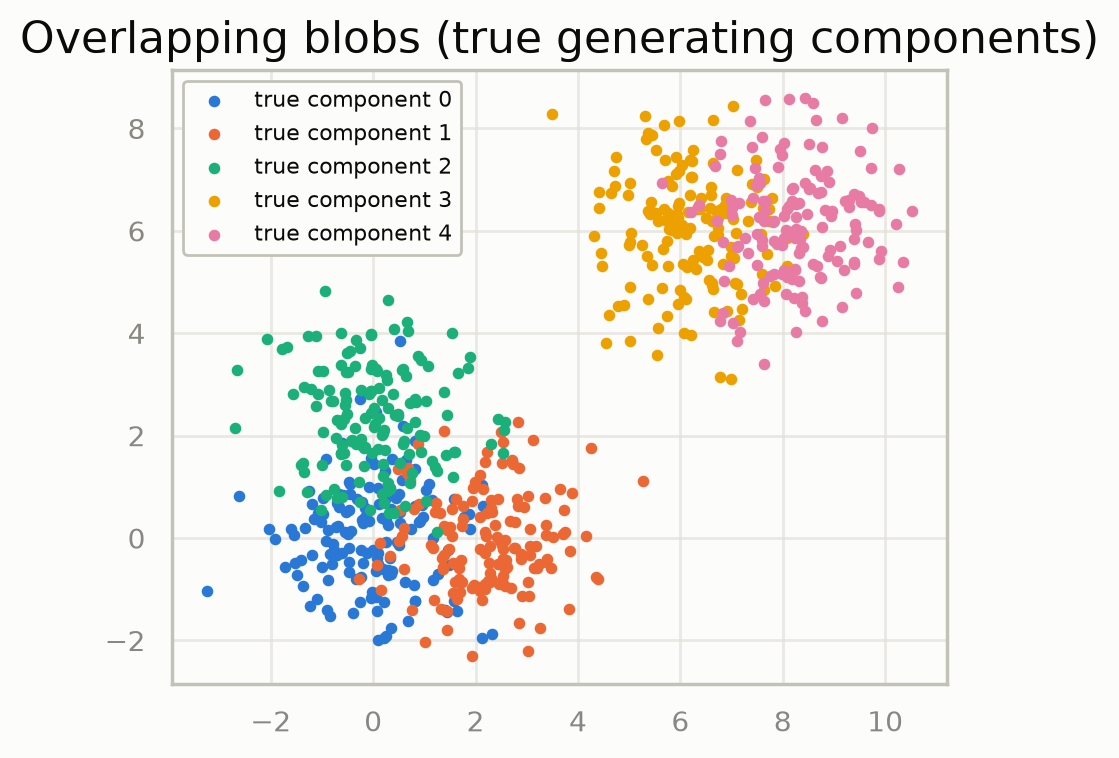

In [ ]:
centers = [
    np.array([0.0, 0.0]),
    np.array([2.2, 0.0]),
    np.array([0.0, 2.2]),
    np.array([6.0, 6.0]),
    np.array([8.2, 6.0]),
]
covs = [np.eye(2) for _ in centers]
n_samples = [150] * len(centers)

X, true_labels = generate_gmm_data(centers, covs, n_samples, random_state=SEED)

plt.figure(figsize=(5, 5))
for _k in range(len(centers)):
    _mask = true_labels == _k
    plt.scatter(X[_mask, 0], X[_mask, 1], s=10, color=CATEGORICAL_PALETTE[_k % len(CATEGORICAL_PALETTE)],
                label=f'true component {_k}')
plt.legend(fontsize=8)
plt.title('Overlapping blobs (true generating components)')
plt.gca().set_aspect('equal')
plt.gcf()

## Sweep `n_components` with `select_model`

`select_model` fits a `GaussianMixture` for every requested `n_components`, recording
`bic`, `aic`, `icl`, the final log-likelihood, and whether each fit converged.

In [ ]:
result = select_model(
    X,
    n_components=range(1, 9),
    covariance_types=('full',),
    criterion='bic',
    n_init=1 if FAST else 3,
    random_state=0,
    max_iter=min(200, MAX_ITER),
)

for row in result.table:
    print(f"K={row['n_components']}  bic={row['bic']:.1f}  aic={row['aic']:.1f}  "
          f"icl={row['icl']:.1f}  icl-bic={row['icl'] - row['bic']:.1f}  converged={row['converged']}")

K=1  bic=7064.1  aic=7041.0  icl=7064.1  icl-bic=0.0  converged=True
K=2  bic=6213.2  aic=6162.4  icl=6213.3  icl-bic=0.1  converged=True
K=3  bic=6191.4  aic=6112.9  icl=6321.4  icl-bic=129.9  converged=True
K=4  bic=6209.7  aic=6103.5  icl=6358.6  icl-bic=148.9  converged=True
K=5  bic=6238.6  aic=6104.6  icl=6482.0  icl-bic=243.4  converged=True
K=6  bic=6275.6  aic=6113.9  icl=6627.2  icl-bic=351.6  converged=True
K=7  bic=6308.3  aic=6118.9  icl=6716.8  icl-bic=408.5  converged=True
K=8  bic=6338.4  aic=6121.2  icl=6748.4  icl-bic=410.0  converged=True


## BIC vs. ICL curves

Both criteria are "lower is better." Watch where each curve's minimum sits.

BIC-optimal K = 3
ICL-optimal K = 2


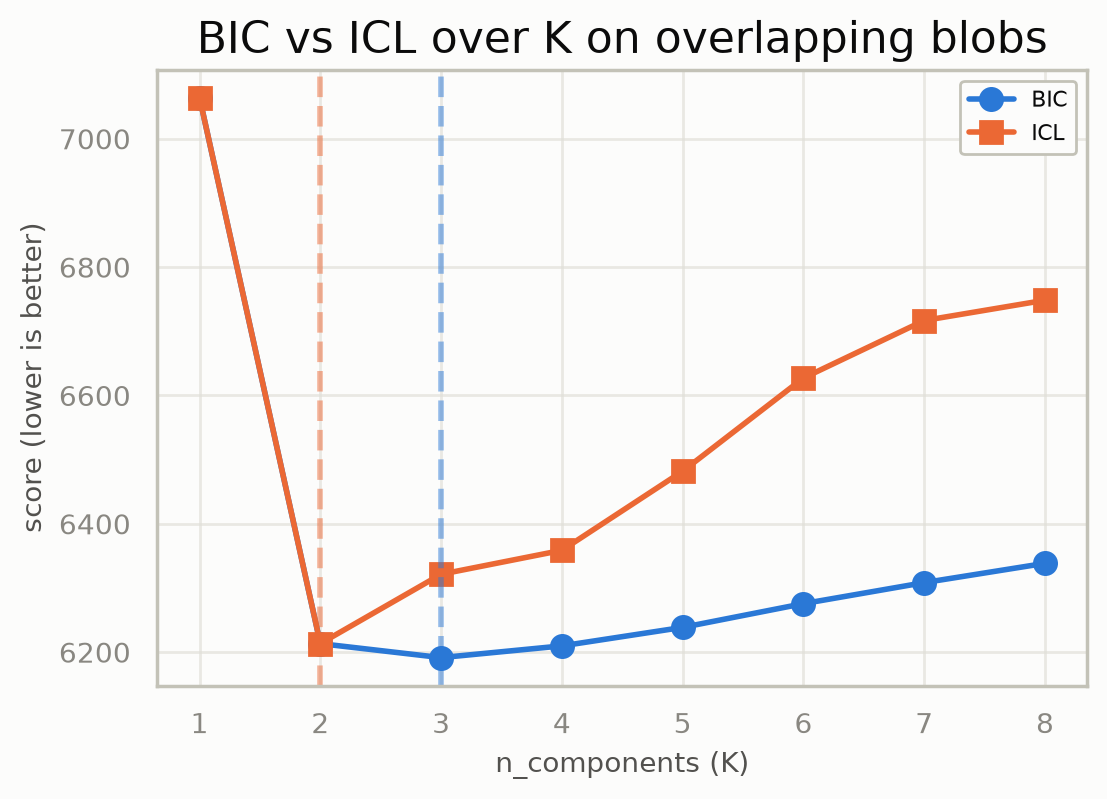

In [ ]:
ks = [row['n_components'] for row in result.table]
bics = [row['bic'] for row in result.table]
icls = [row['icl'] for row in result.table]

best_bic_k = ks[int(np.argmin(bics))]
best_icl_k = ks[int(np.argmin(icls))]

plt.figure(figsize=(6, 4))
plt.plot(ks, bics, marker='o', label='BIC')
plt.plot(ks, icls, marker='s', label='ICL')
plt.axvline(best_bic_k, color='C0', linestyle='--', alpha=0.5)
plt.axvline(best_icl_k, color='C1', linestyle='--', alpha=0.5)
plt.xlabel('n_components (K)')
plt.ylabel('score (lower is better)')
plt.title('BIC vs ICL over K on overlapping blobs')
plt.legend()
print(f'BIC-optimal K = {best_bic_k}')
print(f'ICL-optimal K = {best_icl_k}')
plt.gcf()

As expected on this overlapping dataset, **ICL settles on fewer components than BIC**: BIC
keeps adding components as long as they buy a bit more likelihood, while ICL's entropy penalty
charges for the ambiguity introduced by splitting an overlapping pair into two components whose
responsibilities are never cleanly one-hot. Neither is "wrong" -- they answer different
questions (best density estimate vs. best *well-separated partition*).

`result.best_` is the fitted `GaussianMixture` that minimised the sweep's `criterion` (`'bic'`
here); `result.to_dataframe()` gives the same table as a `pandas.DataFrame` for further analysis.

In [ ]:
print(type(result.best_))
print('best_ n_components:', result.best_.n_components)

df = result.to_dataframe()
df.head()

<class 'tgmm.gmm.GaussianMixture'>
best_ n_components: 3


,n_components,covariance_type,bic,aic,icl,log_likelihood,converged
0,1,full,7064.127921,7041.027555,7064.127921,-4.687352,True
1,2,full,6213.222645,6162.401840,6213.299128,-4.093601,True
2,3,full,6191.434668,6112.893423,6321.353735,-4.052596,True
3,4,full,6209.722469,6103.460785,6358.646404,-4.038307,True
4,5,full,6238.552424,6104.570301,6481.960429,-4.031047,True


## `icl()` on a single fitted model

`icl(X, mode='hard')` (the default) uses the most-likely component per point;
`mode='soft'` uses the full responsibility-entropy penalty instead. Both agree exactly with
`bic()` whenever responsibilities are one-hot (e.g. far-apart, well-separated components), and
diverge more the more overlapping/ambiguous the fit is -- which is exactly what drives the gap
in the curves above.

In [ ]:
gmm = result.models_[(best_bic_k, 'full')]
print('bic:      ', gmm.bic(X))
print('icl hard: ', gmm.icl(X, mode='hard'))
print('icl soft: ', gmm.icl(X, mode='soft'))

bic:       6191.43466759146
icl hard:  6321.353734974273
icl soft:  6435.424779896148


## Summary

- `select_model` sweeps `n_components` (and optionally covariance types) and returns the best fit by the chosen criterion, together with the full table of `bic`, `aic`, `icl`, log-likelihood and convergence for every candidate.
- BIC and AIC measure fit versus complexity; ICL adds an entropy penalty, so on overlapping clusters it favors fewer, better-separated components.
- Neither criterion is wrong -- they answer different questions: the best density estimate versus the best-separated partition.
- `icl(X, mode='hard' | 'soft')` can be computed on any fitted model; it equals BIC when responsibilities are one-hot.

**Next:** [14 -- Stochastic EM, Annealing and SAEM](14_stochastic_em.ipynb) for fitting algorithms that escape poor local optima, and [15 -- Covariance Structures](15_covariance_models.ipynb) for sweeping all 14 covariance models with `select_model`.